# Clase 7 — Visualización exploratoria

**Laboratorio de Modelo Analítico para la Toma de Decisiones**
ISTEA · 2026-2C · División A

---

La clase pasada llegamos a hallazgos escritos. Hoy los mostramos.

Un gráfico no es una decoración del informe: **es el argumento**. Y un gráfico mal
elegido no es feo, es falso — hace ver una relación que no existe, o esconde una que sí.

| Parte | Qué es | Cuándo |
| --- | --- | --- |
| **A** | De la anatomía de una figura al caso ECS-SOI | Lo hacemos juntos |
| **B** | Los gráficos de **tu** dataset | Segunda hora, en equipo |

> **Lo más importante está en A13, A14 y A15.** Vamos a hacer el gráfico que la
> Dirección quiere ver y vamos a descubrir que miente. No porque los datos estén mal,
> sino por cómo construimos la variable.

**Dos oficios distintos.** Un gráfico *para explorar* lo mirás vos: feo está bien,
rápido importa más que lindo, se hacen veinte y se tiran diecinueve. Un gráfico *para
comunicar* lo mira alguien que decide: es uno solo y tiene que sostener una
afirmación. Hoy hacemos los dos.

---
# PARTE A · ElecCommSphere

## A0 · El punto de partida

Además de la limpieza de la clase 4, agregamos un paso que hoy hace falta:
**normalizar el texto de `categoria`**. En el archivo crudo hay 17 variantes
—`Electronica`, `ELECTRONICA`, `Electrónica `, con espacios y tildes— que en realidad
son 5 categorías.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"]      = True
plt.rcParams["grid.alpha"]     = 0.3
plt.rcParams["axes.spines.top"]   = False
plt.rcParams["axes.spines.right"] = False

AZUL, GRIS, ROJO, VERDE = "#0A2FF1", "#6E7280", "#B4341F", "#1E7A46"

tx  = pd.read_csv("eleccommsphere_transacciones.csv", parse_dates=["fecha"])
cli = pd.read_csv("eleccommsphere_clientes.csv", parse_dates=["fecha_alta"])

t = tx.drop_duplicates()
t = t[t["id_cliente"].isin(cli["id_cliente"])]

print("Categorías antes de normalizar :", t["categoria"].nunique())
t["categoria"] = (t["categoria"].str.strip().str.lower()
                    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("utf-8"))
print("Categorías después             :", t["categoria"].nunique())

t = t[t["monto"].notna() & (t["monto"] > 0)]
t = t[t["monto"] <= t["monto"].quantile(0.999)]
print(f"\nFilas limpias: {len(t):,}")

Categorías antes de normalizar : 17
Categorías después             : 5

Filas limpias: 25,369


## A1 · La anatomía de una figura

Dos piezas y se entiende todo matplotlib:

- **`fig`** es la hoja: el tamaño y el conjunto.
- **`ax`** son los ejes: un cuadro de dibujo dentro de la hoja.

`plt.subplots(1, 2)` devuelve dos cuadros: `ax[0]` y `ax[1]`. Casi todo lo que se
configura se le pide al `ax`, no al `plt`.

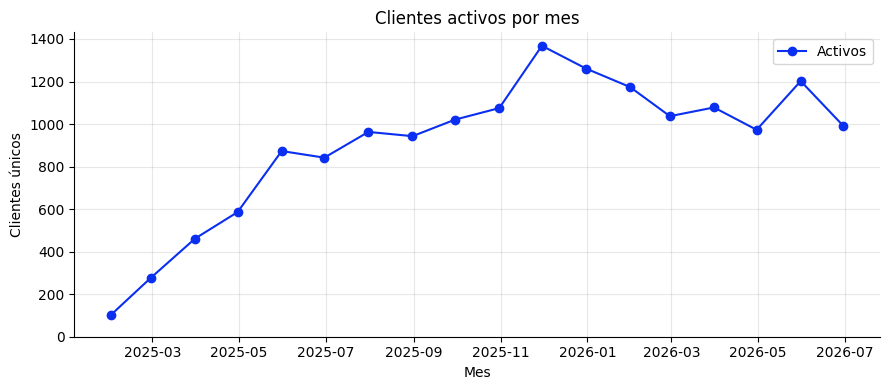

In [3]:
mensual = (t.set_index("fecha")
             .resample("ME")
             .agg(facturacion = ("monto",      "sum"),
                  activos     = ("id_cliente", "nunique"),
                  ticket      = ("monto",      "median")))

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(mensual.index, mensual["activos"], marker="o", color=AZUL, label="Activos")

ax.set_title("Clientes activos por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Clientes únicos")
ax.set_ylim(0, None)          # el eje arranca en cero
ax.legend()

plt.tight_layout()
plt.show()

## A2 · El histograma, y por qué los bins cambian la historia

Un histograma responde **¿cómo se distribuye?**. La cantidad de barras no es un
detalle estético: cambia lo que el gráfico parece decir.

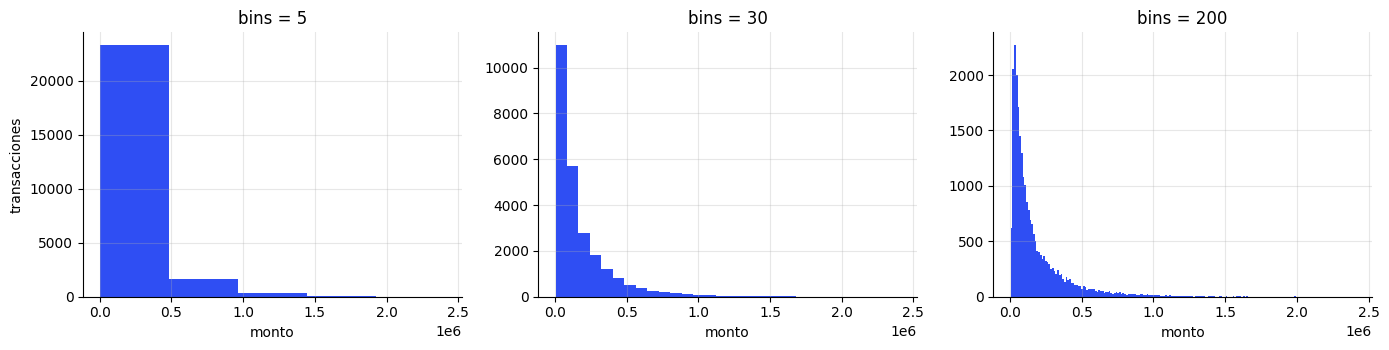

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, b in zip(ax, [5, 30, 200]):
    a.hist(t["monto"], bins=b, color=AZUL, alpha=.85)
    a.set_title(f"bins = {b}")
    a.set_xlabel("monto")
ax[0].set_ylabel("transacciones")
plt.tight_layout(); plt.show()

Con 5 barras parece que casi todo está en un solo lugar. Con 200 aparece ruido que no
significa nada. **No hay un número correcto**, pero sí una obligación: probar varios
antes de concluir, y decir cuál usaste.

## A3 · Cuándo pasar a logaritmo

Regla práctica: **si el máximo es más de cien veces la mediana, probá escala
logarítmica.**

In [5]:
print(f"Mediana : $ {t['monto'].median():,.0f}")
print(f"Máximo  : $ {t['monto'].max():,.0f}")
print(f"Razón   : {t['monto'].max()/t['monto'].median():.0f} veces")

Mediana : $ 102,244
Máximo  : $ 2,403,171
Razón   : 24 veces


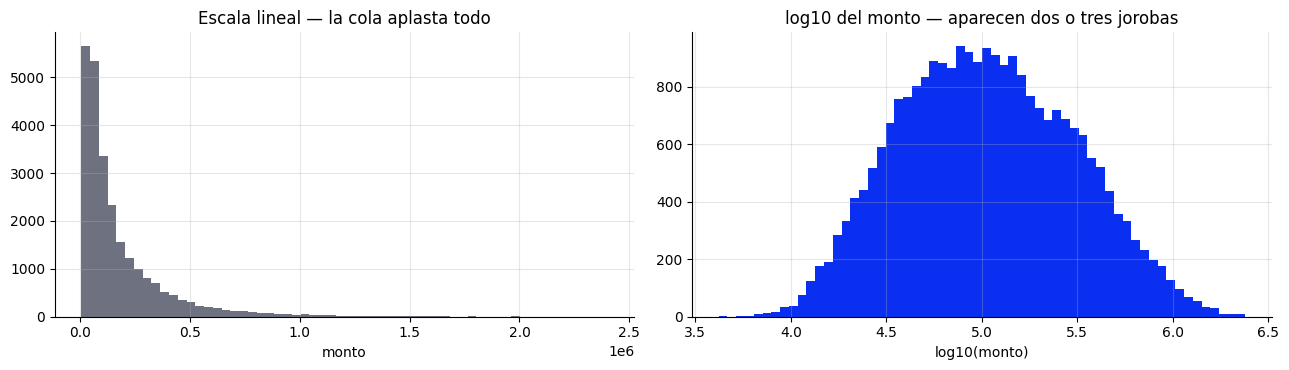

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))

ax[0].hist(t["monto"], bins=60, color=GRIS)
ax[0].set_title("Escala lineal — la cola aplasta todo")
ax[0].set_xlabel("monto")

ax[1].hist(np.log10(t["monto"]), bins=60, color=AZUL)
ax[1].set_title("log10 del monto — aparecen dos o tres jorobas")
ax[1].set_xlabel("log10(monto)")

plt.tight_layout(); plt.show()

> **El costo del logaritmo:** el eje deja de ser intuitivo. «4,7» no significa nada
> para quien no sabe que son $ 50.000. En un tablero para Dirección, evitalo salvo que
> lo expliques. En exploración, usalo cuando haga falta.

**Mirá la joroba de la derecha.** El histograma en log no es una campana: tiene
bultos. Eso casi siempre significa que adentro hay más de una población. Lo vemos
ahora.

## A4 · El promedio mezclaba cinco poblaciones

La clase pasada dijimos que la media ($ 182.811) está 79 % por encima de la mediana
($ 102.244). La explicación fácil era «hay compras muy grandes». La explicación real
es otra.

In [7]:
por_cat = t.groupby("categoria").agg(
    operaciones = ("monto", "size"),
    mediana     = ("monto", "median"),
    p25         = ("monto", lambda s: s.quantile(.25)),
    p75         = ("monto", lambda s: s.quantile(.75)),
).sort_values("mediana").round(0)

por_cat["veces_vs_mas_barata"] = (por_cat["mediana"] / por_cat["mediana"].min()).round(1)
por_cat

,operaciones,mediana,p25,p75,veces_vs_mas_barata
categoria,,,,,
accesorios,3798,31077.0,20259.0,49768.0,1.0
indumentaria,6357,54176.0,35125.0,84897.0,1.7
hogar,4539,87437.0,56540.0,137819.0,2.8
electronica,7658,206401.0,131774.0,327230.0,6.6
electrodomesticos,3017,445625.0,287619.0,706598.0,14.3


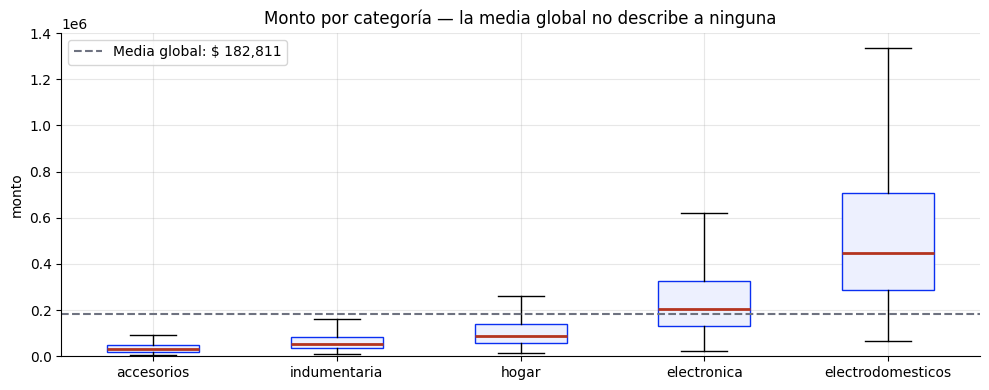

In [8]:
orden = por_cat.index.tolist()
datos = [t.loc[t["categoria"] == c, "monto"] for c in orden]

fig, ax = plt.subplots(figsize=(10, 4))
bp = ax.boxplot(datos, showfliers=False, patch_artist=True)
ax.set_xticks(range(1, len(orden) + 1)); ax.set_xticklabels(orden)
for caja in bp["boxes"]:
    caja.set_facecolor("#EDF0FE"); caja.set_edgecolor(AZUL)
for med in bp["medians"]:
    med.set_color(ROJO); med.set_linewidth(2)

ax.axhline(t["monto"].mean(), ls="--", color=GRIS,
           label=f"Media global: $ {t['monto'].mean():,.0f}")
ax.set_title("Monto por categoría — la media global no describe a ninguna")
ax.set_ylabel("monto"); ax.set_ylim(0, None); ax.legend()
plt.tight_layout(); plt.show()

> **El hallazgo.** Electrodomésticos tiene una mediana 14 veces más alta que
> accesorios. **No hay un «monto típico» de ElecCommSphere: hay cinco.** La línea
> punteada —el promedio global— no pasa por el medio de ninguna caja.
>
> La pregunta de negocio deja de ser *«cuánto gasta un cliente»* y pasa a ser *«qué
> compra»*. Eso es lo que hace un EDA cuando funciona: cambia la pregunta.

## A5 · Cómo se lee un boxplot

Aprovechemos la edad de los clientes, que todavía tiene los valores imposibles que
detectamos en la clase 4.

| Parte | Qué es |
| --- | --- |
| La caja | Del primer al tercer cuartil: adentro está la mitad del medio |
| La línea de adentro | La **mediana**, no la media |
| Los bigotes | Hasta 1,5 veces el rango intercuartílico — no el mínimo y el máximo |
| Los puntos sueltos | Quedan fuera de los bigotes. No son necesariamente errores |

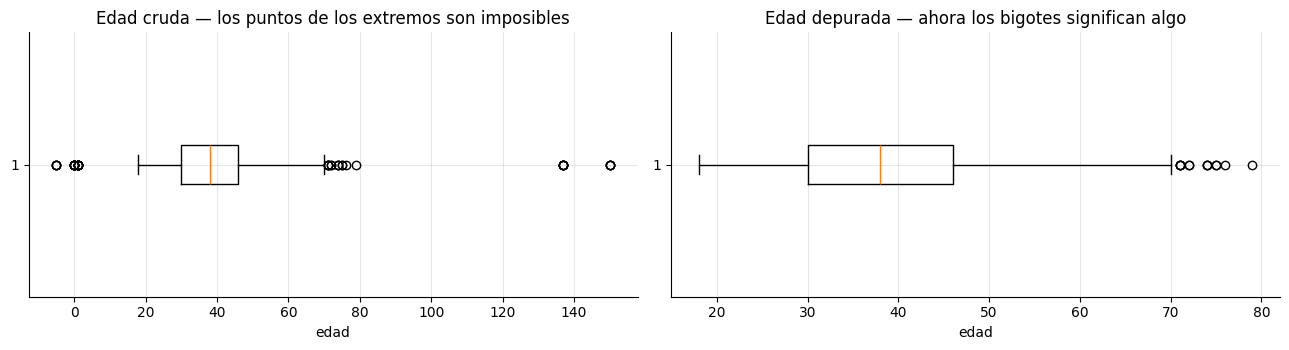

Edad cruda    : mín -5, máx 150, media 38.5
Edad depurada : mín 18, máx 79, media 38.4


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))

ax[0].boxplot(cli["edad"].dropna(), vert=False)
ax[0].set_title("Edad cruda — los puntos de los extremos son imposibles")
ax[0].set_xlabel("edad")

edad_ok = cli["edad"].where((cli["edad"] >= 16) & (cli["edad"] <= 100)).dropna()
ax[1].boxplot(edad_ok, vert=False)
ax[1].set_title("Edad depurada — ahora los bigotes significan algo")
ax[1].set_xlabel("edad")

plt.tight_layout(); plt.show()

print(f"Edad cruda    : mín {cli['edad'].min():.0f}, máx {cli['edad'].max():.0f}, media {cli['edad'].mean():.1f}")
print(f"Edad depurada : mín {edad_ok.min():.0f}, máx {edad_ok.max():.0f}, media {edad_ok.mean():.1f}")

> **Lo que el boxplot no muestra:** si la distribución tiene dos picos. Un boxplot y
> un histograma de los mismos datos pueden contar historias distintas, y ninguno
> miente: el boxplot resume, el histograma muestra la forma. En exploración, hacé los
> dos.

## A6 · Dispersión: veinticinco mil puntos no entran

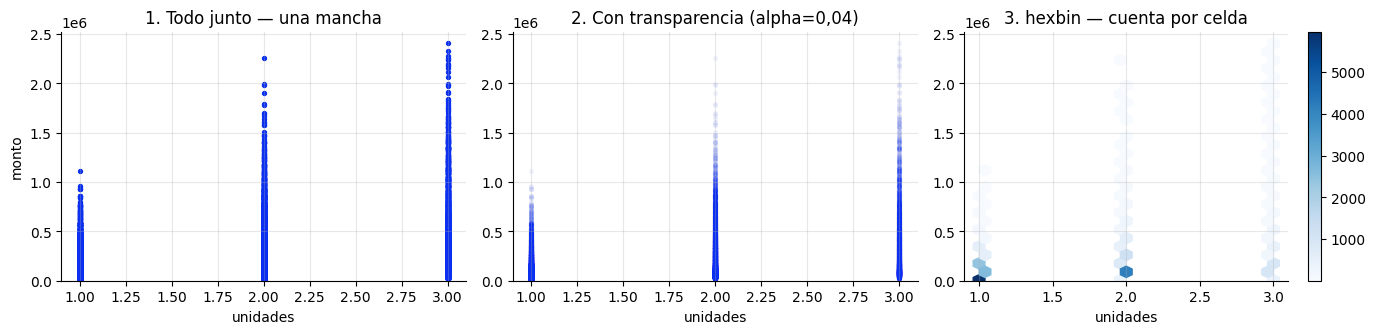

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

ax[0].scatter(t["unidades"], t["monto"], s=8, color=AZUL)
ax[0].set_title("1. Todo junto — una mancha")

ax[1].scatter(t["unidades"], t["monto"], s=8, color=AZUL, alpha=0.04)
ax[1].set_title("2. Con transparencia (alpha=0,04)")

hb = ax[2].hexbin(t["unidades"], t["monto"], gridsize=25, cmap="Blues", mincnt=1)
ax[2].set_title("3. hexbin — cuenta por celda")
plt.colorbar(hb, ax=ax[2])

for a in ax:
    a.set_xlabel("unidades"); a.set_ylim(0, None)
ax[0].set_ylabel("monto")
plt.tight_layout(); plt.show()

**Cuál usar:** hasta unos mil puntos, `scatter` directo. Entre mil y cien mil, `alpha`
bajo. Más que eso, `hexbin` o un muestreo aleatorio (`df.sample(2000)`), que es
legítimo para explorar y hay que declararlo si el gráfico va al informe.

> Una mancha negra uniforme no es un gráfico saturado: es un gráfico que no se hizo.

## A7 · El cuarteto de Anscombe

Cuatro conjuntos de datos con la **misma media, el mismo desvío y la misma
correlación**. Antes de graficar: ¿se parecen entre sí?

In [11]:
anscombe = {
 "I":   ([10,8,13,9,11,14,6,4,12,7,5],
         [8.04,6.95,7.58,8.81,8.33,9.96,7.24,4.26,10.84,4.82,5.68]),
 "II":  ([10,8,13,9,11,14,6,4,12,7,5],
         [9.14,8.14,8.74,8.77,9.26,8.10,6.13,3.10,9.13,7.26,4.74]),
 "III": ([10,8,13,9,11,14,6,4,12,7,5],
         [7.46,6.77,12.74,7.11,7.81,8.84,6.08,5.39,8.15,6.42,5.73]),
 "IV":  ([8,8,8,8,8,8,8,19,8,8,8],
         [6.58,5.76,7.71,8.84,8.47,7.04,5.25,12.50,5.56,7.91,6.89]),
}

resumen_ans = pd.DataFrame({
    k: {"media x": np.mean(x), "media y": np.mean(y),
        "desvío y": np.std(y, ddof=1), "correlación": np.corrcoef(x, y)[0, 1]}
    for k, (x, y) in anscombe.items()
}).T.round(3)
resumen_ans

,media x,media y,desvío y,correlación
I,9.0,7.501,2.032,0.816
II,9.0,7.501,2.032,0.816
III,9.0,7.500,2.030,0.816
IV,9.0,7.501,2.031,0.817


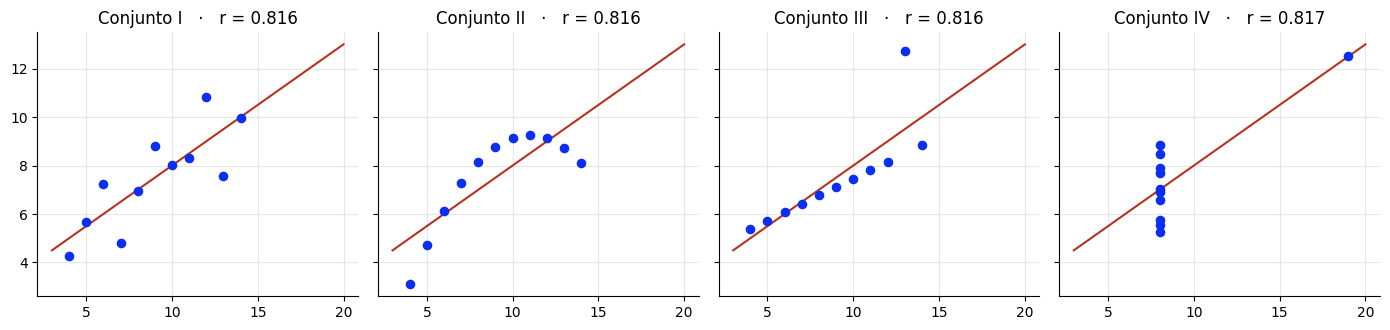

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True, sharey=True)
for a, (k, (x, y)) in zip(ax, anscombe.items()):
    x, y = np.array(x), np.array(y)
    a.scatter(x, y, color=AZUL, s=35, zorder=3)
    m, b = np.polyfit(x, y, 1)
    xs = np.linspace(3, 20, 10)
    a.plot(xs, m*xs + b, color=ROJO, lw=1.5)
    a.set_title(f"Conjunto {k}   ·   r = {np.corrcoef(x, y)[0,1]:.3f}")
plt.tight_layout(); plt.show()

Cuatro historias opuestas, cuatro veces los mismos números:

| Conjunto | Qué es en realidad |
| --- | --- |
| I | Una relación lineal con ruido. El único donde la correlación describe bien |
| II | Una curva perfecta. La correlación lineal no captura nada |
| III | Una recta casi exacta arruinada por **un solo punto** |
| IV | Diez puntos en una vertical y uno lejos. Ese punto genera toda la correlación |

> Anscombe armó estos datos en 1973 para discutir exactamente esto. Sigue siendo el
> mejor argumento a favor de graficar antes de resumir — y aplica igual a la matriz de
> correlación que viene ahora.

## A8 · La matriz de correlación, y lo que dice de nuestro caso

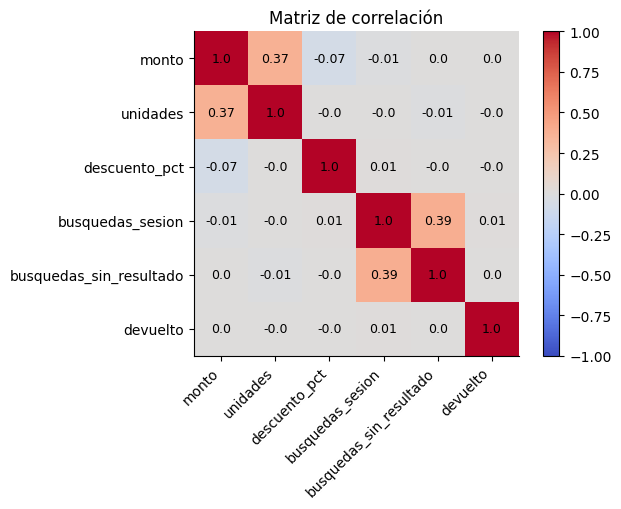

In [13]:
num = t[["monto", "unidades", "descuento_pct", "busquedas_sesion",
         "busquedas_sin_resultado", "devuelto"]]
corr = num.corr().round(2)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=9)
plt.colorbar(im); ax.set_title("Matriz de correlación"); ax.grid(False)
plt.tight_layout(); plt.show()

**Las únicas dos correlaciones del dataset son mecánicas:**

- `monto ~ unidades` = 0,37 → comprar más cosas cuesta más plata. No es un hallazgo.
- `búsquedas ~ búsquedas sin resultado` = 0,39 → quien busca más falla más veces en
  términos absolutos. Tampoco.

Todo el resto está en cero. **Que la matriz esté vacía no significa que no haya
relaciones**: significa que no hay relaciones lineales entre pares de columnas crudas.
La señal del proyecto ECS-SOI existe, pero aparece recién cuando construimos variables
**por cliente** — que es lo que hacemos en A13.

> Lo que el mapa de calor muestra: que dos variables se mueven juntas, y con qué
> intensidad. Lo que no muestra: quién causa qué. Con veinte variables hay 190 pares y
> alguno va a dar alto por puro azar.

## A9 · El eje truncado: la manipulación más común

Los dos gráficos de abajo usan **exactamente los mismos datos**.

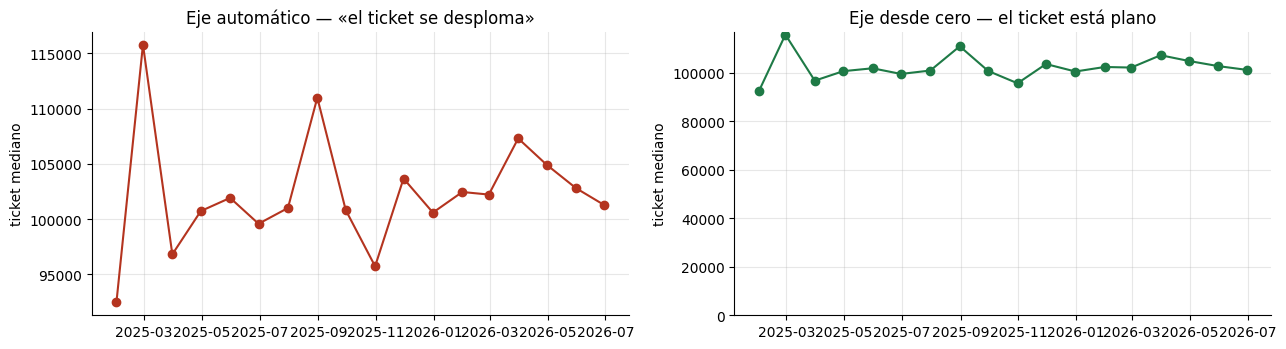

Ticket mínimo: $ 92,449
Ticket máximo: $ 115,785
Variación    : 25.2%


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))

ax[0].plot(mensual.index, mensual["ticket"], marker="o", color=ROJO)
ax[0].set_title("Eje automático — «el ticket se desploma»")

ax[1].plot(mensual.index, mensual["ticket"], marker="o", color=VERDE)
ax[1].set_ylim(0, None)
ax[1].set_title("Eje desde cero — el ticket está plano")

for a in ax: a.set_ylabel("ticket mediano")
plt.tight_layout(); plt.show()

print(f"Ticket mínimo: $ {mensual['ticket'].min():,.0f}")
print(f"Ticket máximo: $ {mensual['ticket'].max():,.0f}")
print(f"Variación    : {mensual['ticket'].max()/mensual['ticket'].min()-1:.1%}")

El de la izquierda justificaría un proyecto de pricing. El de la derecha dice que no
hace falta. **La diferencia es una línea de código**, y muchas veces no es
intencional: es el valor por defecto de matplotlib.

## A10 · La media móvil: la tendencia bajo el ruido

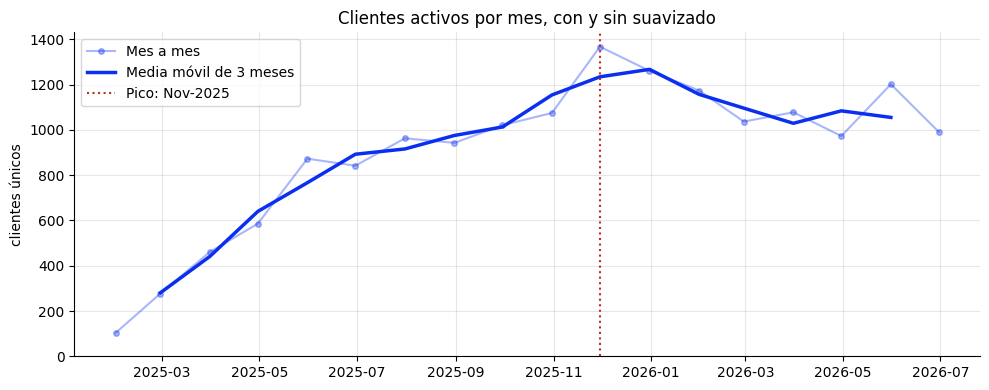

In [15]:
serie = mensual["activos"]
suave = serie.rolling(3, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie.index, serie, marker="o", ms=4, alpha=.35, color=AZUL, label="Mes a mes")
ax.plot(suave.index, suave, lw=2.5, color=AZUL, label="Media móvil de 3 meses")
ax.axvline(serie.idxmax(), ls=":", color=ROJO, label=f"Pico: {serie.idxmax():%b-%Y}")
ax.set_title("Clientes activos por mes, con y sin suavizado")
ax.set_ylabel("clientes únicos"); ax.set_ylim(0, None); ax.legend()
plt.tight_layout(); plt.show()

La ventana se elige según el ciclo del negocio: 3 meses para una tendencia general, 12
para sacarle la estacionalidad a una serie mensual. `center=True` la centra; sin eso
queda corrida hacia adelante.

> **Mostrá siempre la serie cruda y la suavizada juntas.** La suavizada sola esconde
> la variabilidad real, y esa variabilidad es información.

## A11 · Pequeños múltiplos: cinco cuadros chicos en vez de cinco líneas

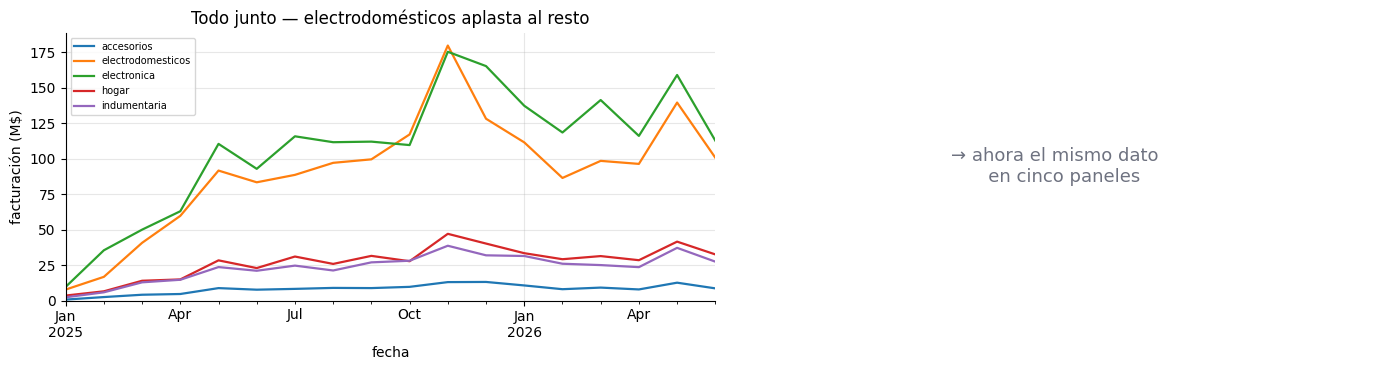

In [16]:
serie_cat = (t.set_index("fecha")
               .groupby("categoria")
               .resample("ME")["monto"].sum()
               .unstack(0) / 1e6)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
serie_cat.plot(ax=ax[0], lw=1.6)
ax[0].set_title("Todo junto — electrodomésticos aplasta al resto")
ax[0].set_ylabel("facturación (M$)"); ax[0].set_ylim(0, None)
ax[0].legend(fontsize=7)

ax[1].axis("off")
ax[1].text(.5, .5, "→ ahora el mismo dato\n   en cinco paneles",
           ha="center", va="center", fontsize=13, color=GRIS)
plt.tight_layout(); plt.show()

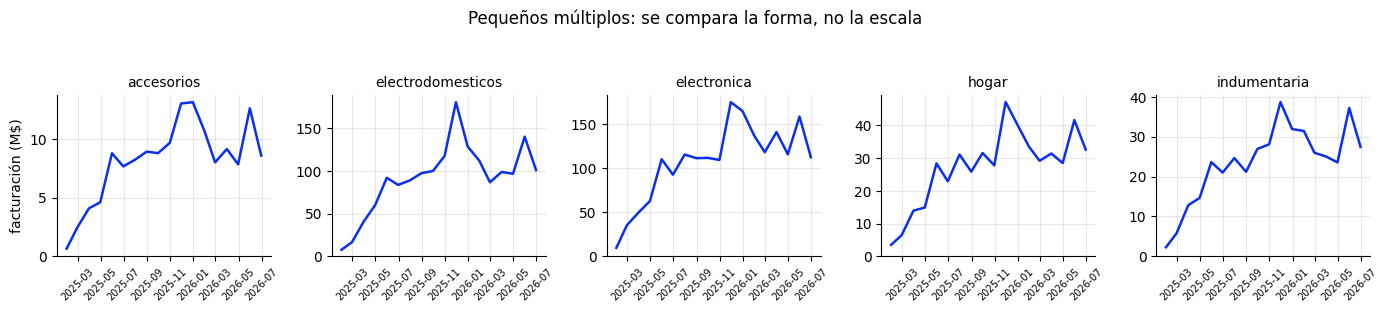

In [17]:
cats = serie_cat.columns.tolist()
fig, ax = plt.subplots(1, len(cats), figsize=(14, 2.9), sharex=True)
for a, c in zip(ax, cats):
    a.plot(serie_cat.index, serie_cat[c], color=AZUL, lw=1.8)
    a.set_title(c, fontsize=10)
    a.set_ylim(0, None)
    a.tick_params(axis="x", rotation=45, labelsize=7)
ax[0].set_ylabel("facturación (M$)")
fig.suptitle("Pequeños múltiplos: se compara la forma, no la escala", y=1.06)
plt.tight_layout(); plt.show()

En el primero solo se ve electrodomésticos. En los cinco paneles se ve **la forma de
cada serie**, que es lo que interesa cuando las escalas son muy distintas.

> Regla práctica: más de cuatro series en un mismo cuadro casi siempre son pequeños
> múltiplos mal resueltos. Si hay que mirar la leyenda para saber qué línea es cuál,
> el gráfico ya falló.

## A12 · Barras: comparar categorías

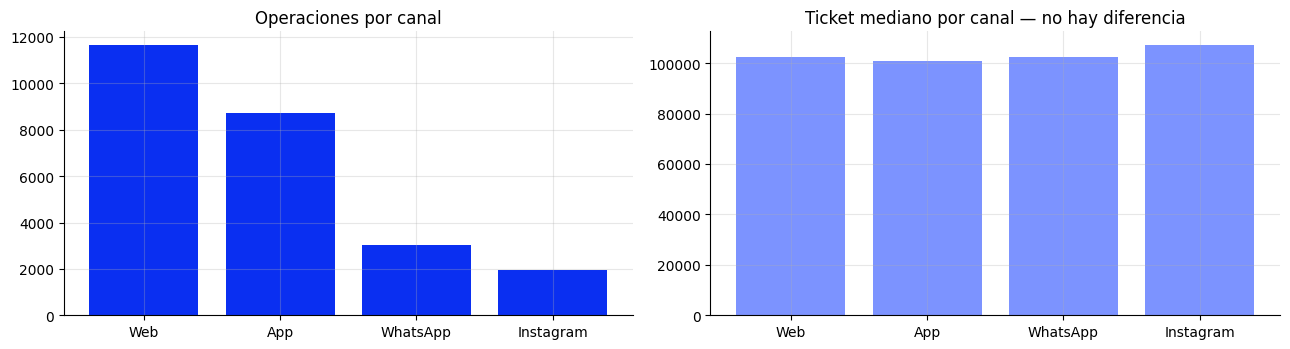

,operaciones,ticket
canal,,
Web,11660,102315.0
App,8718,100878.0
WhatsApp,3050,102349.0
Instagram,1941,107217.0


In [18]:
por_canal = t.groupby("canal").agg(
    operaciones = ("monto", "size"),
    ticket      = ("monto", "median"),
).sort_values("operaciones", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(por_canal.index, por_canal["operaciones"], color=AZUL)
ax[0].set_ylim(0, None); ax[0].set_title("Operaciones por canal")

ax[1].bar(por_canal.index, por_canal["ticket"], color="#7C93FF")
ax[1].set_ylim(0, None); ax[1].set_title("Ticket mediano por canal — no hay diferencia")

plt.tight_layout(); plt.show()
por_canal.round(0)

El de la derecha es un gráfico **que no muestra nada, y eso es lo que muestra**: los
cuatro canales son iguales. Si el eje no empezara en cero, esas cuatro barras
parecerían muy distintas.

## A13 · El caso ECS-SOI: el gráfico que la Dirección quiere ver

La hipótesis del proyecto es razonable: **si el buscador no encuentra lo que el
cliente busca, el cliente compra menos y termina yéndose.**

Primero separamos el tiempo en dos ventanas, como se hace siempre que hay que medir
abandono: **observamos** hasta el 31/03/2026 y **miramos el resultado** después.

In [19]:
CORTE = pd.Timestamp("2026-03-31")
obs  = t[t["fecha"] <= CORTE]
post = t[t["fecha"] >  CORTE]

print(f"Observación : {obs['fecha'].min().date()} → {obs['fecha'].max().date()}  ({len(obs):,} tx)")
print(f"Resultado   : {post['fecha'].min().date()} → {post['fecha'].max().date()}  ({len(post):,} tx)")

v = obs.groupby("id_cliente").agg(
    compras  = ("id_transaccion",          "count"),
    gasto    = ("monto",                   "sum"),
    busq     = ("busquedas_sesion",        "sum"),
    fallidas = ("busquedas_sin_resultado", "sum"),
)
v["pct_fallidas"] = v["fallidas"] / v["busq"]
v = v[v["compras"] >= 2].copy()        # hace falta historia para hablar de abandono
v["churn"] = ~v.index.isin(post["id_cliente"])

print(f"\nClientes analizados : {len(v):,}")
print(f"Tasa de abandono    : {v['churn'].mean():.1%}")

Observación : 2025-01-06 → 2026-03-31  (20,188 tx)
Resultado   : 2026-04-01 → 2026-06-30  (5,181 tx)

Clientes analizados : 2,547
Tasa de abandono    : 40.1%


In [20]:
v["quintil"] = pd.qcut(v["pct_fallidas"], 5,
                       labels=["Q1 (mejor)", "Q2", "Q3", "Q4", "Q5 (peor)"])

resumen = v.groupby("quintil", observed=True).agg(
    clientes  = ("compras", "size"),
    compras   = ("compras", "mean"),
    gasto     = ("gasto",   "mean"),
    busquedas = ("busq",    "mean"),     # ← acordate de esta columna
    churn     = ("churn",   "mean"),
)
resumen["churn"] = (resumen["churn"] * 100).round(1)
resumen.round(1)

,clientes,compras,gasto,busquedas,churn
quintil,,,,,
Q1 (mejor),510,6.8,1266483.8,24.0,38.8
Q2,520,7.4,1366048.6,26.3,38.5
Q3,503,8.8,1573656.0,31.9,35.4
Q4,508,8.9,1624103.0,32.1,40.6
Q5 (peor),506,6.7,1241156.9,23.9,47.4


**Pará acá y mirá la tabla antes de seguir.** ¿Q5 —el peor quintil de búsqueda—
compra menos que Q1?

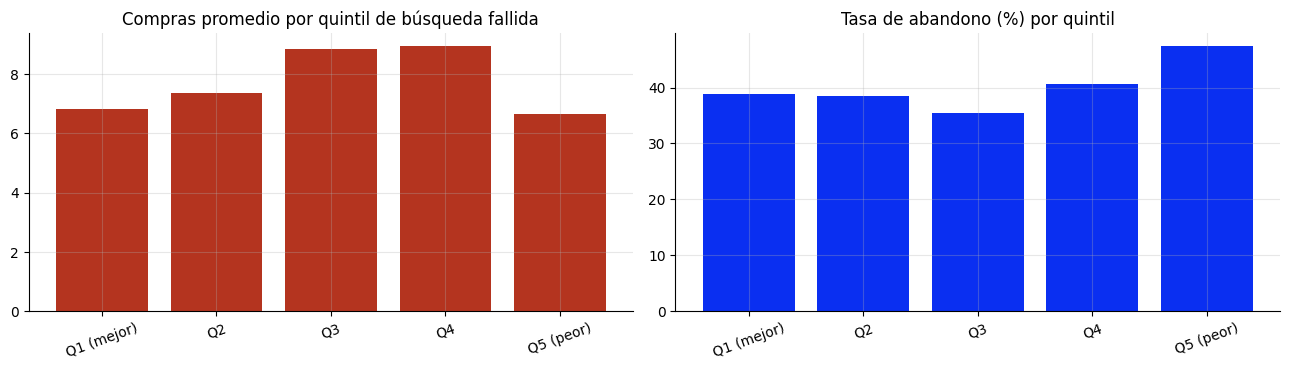

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))

ax[0].bar(resumen.index.astype(str), resumen["compras"], color=ROJO)
ax[0].set_ylim(0, None)
ax[0].set_title("Compras promedio por quintil de búsqueda fallida")
ax[0].tick_params(axis="x", rotation=20)

ax[1].bar(resumen.index.astype(str), resumen["churn"], color=AZUL)
ax[1].set_ylim(0, None)
ax[1].set_title("Tasa de abandono (%) por quintil")
ax[1].tick_params(axis="x", rotation=20)

plt.tight_layout(); plt.show()

El gráfico de la izquierda **no es una pendiente: es una U invertida.** Q1 y Q5 —los
dos extremos— compran casi lo mismo, y los del medio compran más que los dos.

Si le mostrás esto a la Dirección para justificar el proyecto, el proyecto se cae.

## A14 · Por qué miente: el problema está en el denominador

Mirá la columna que casi no miramos: **búsquedas promedio**.

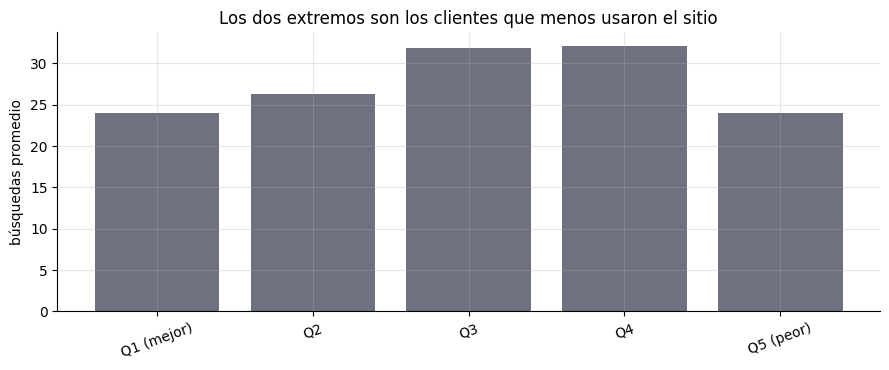

,clientes,busquedas,compras,churn
quintil,,,,
Q1 (mejor),510,24.0,6.8,38.8
Q2,520,26.3,7.4,38.5
Q3,503,31.9,8.8,35.4
Q4,508,32.1,8.9,40.6
Q5 (peor),506,23.9,6.7,47.4


In [22]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(5)
ax.bar(x, resumen["busquedas"], color=GRIS)
ax.set_xticks(x); ax.set_xticklabels(resumen.index.astype(str), rotation=20)
ax.set_ylim(0, None); ax.set_ylabel("búsquedas promedio")
ax.set_title("Los dos extremos son los clientes que menos usaron el sitio")
plt.tight_layout(); plt.show()

resumen[["clientes", "busquedas", "compras", "churn"]].round(1)

Q1 tiene 24,0 búsquedas promedio. Q5 tiene 23,9. Q3 —el del medio— tiene 31,9.

`pct_fallidas` es un cociente: fallidas sobre búsquedas totales.

- Con 3 búsquedas y 1 fallida da 33 %.
- Con 40 búsquedas y 13 fallidas da lo mismo.
- Pero el primero es ruido y el segundo es una medición.

Un ratio estimado sobre pocas observaciones es inestable, y **empuja a los casos de
poca actividad hacia los dos extremos**. Q1 y Q5 no son «los que buscan bien» y «los
que buscan mal»: son, en buena medida, los que casi no buscaron.

> Esto pasa en **cualquier métrica de tasa**: conversión, click-through, porcentaje de
> devolución, calificación promedio. Si en su dataset construyeron un porcentaje,
> tienen este problema hasta que demuestren lo contrario.

## A15 · La señal existe: hay que saber dónde mirar

Dos cosas rescatan el proyecto. **Primera: en el churn sí se ve** — de 38,8 % a
47,4 %, casi nueve puntos. **Segunda: si controlamos el denominador, se ordena.**

In [23]:
def churn_por_quintil(df, etiqueta):
    d = df.copy()
    d["q"] = pd.qcut(d["pct_fallidas"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
    s = d.groupby("q", observed=True)["churn"].mean()
    print(f"{etiqueta:34s} " + "  ".join(f"{x:.1%}" for x in s))
    return s

print("Tasa de abandono por quintil de búsqueda fallida")
print("-" * 72)
s_todos = churn_por_quintil(v,                  f"todos (n={len(v):,})")
s_act   = churn_por_quintil(v[v["busq"] >= 10], f"con 10+ búsquedas (n={(v['busq']>=10).sum():,})")

Tasa de abandono por quintil de búsqueda fallida
------------------------------------------------------------------------
todos (n=2,547)                    38.8%  38.5%  35.4%  40.6%  47.4%
con 10+ búsquedas (n=2,106)        35.2%  31.7%  33.0%  37.3%  41.7%


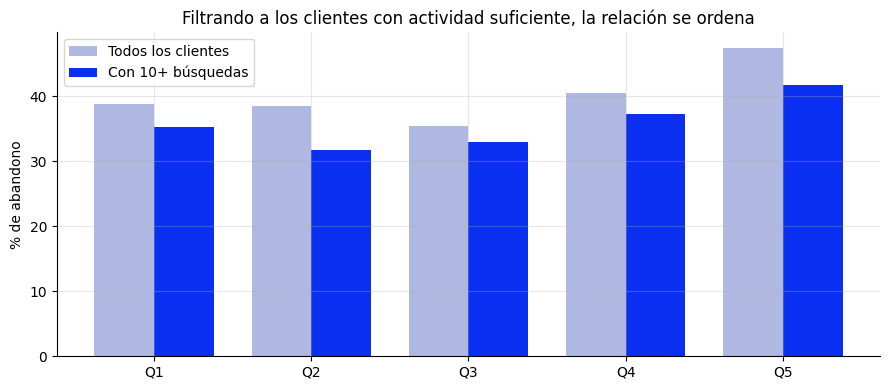

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(5); w = 0.38
ax.bar(x - w/2, s_todos * 100, w, label="Todos los clientes", color="#AFB8E0")
ax.bar(x + w/2, s_act   * 100, w, label="Con 10+ búsquedas",  color=AZUL)
ax.set_xticks(x); ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"])
ax.set_ylim(0, None); ax.set_ylabel("% de abandono")
ax.set_title("Filtrando a los clientes con actividad suficiente, la relación se ordena")
ax.legend(); plt.tight_layout(); plt.show()

> **La moraleja.** El gráfico de una variable sola no alcanzó. No porque no hubiera
> señal, sino porque una variable de confusión —cuánto usa el sitio cada cliente— se
> comía el efecto.
>
> En la clase 12 la regresión logística va a recuperar esta variable con coeficiente
> positivo, porque la mira **controlando** por recencia, frecuencia y monto al mismo
> tiempo. Eso es lo que justifica hacer un modelo en vez de quedarse con gráficos.

## A16 · Guardar una figura para el informe

El gráfico que va al TP no se saca con una captura de pantalla.

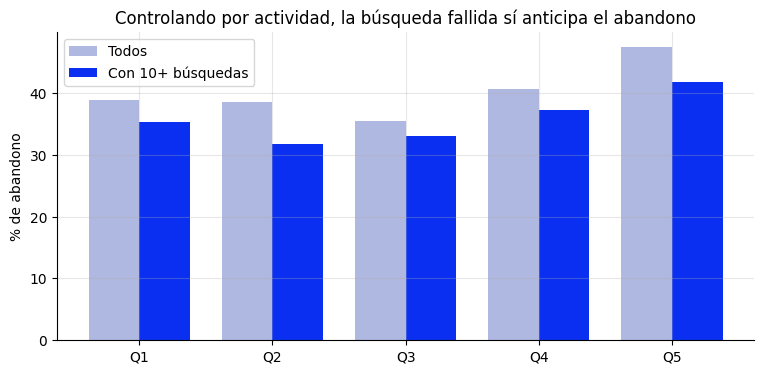

Guardado como grafico_ecs_soi.png


In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(np.arange(5) - .19, s_todos * 100, .38, label="Todos", color="#AFB8E0")
ax.bar(np.arange(5) + .19, s_act   * 100, .38, label="Con 10+ búsquedas", color=AZUL)
ax.set_xticks(range(5)); ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"])
ax.set_ylim(0, None); ax.set_ylabel("% de abandono")
ax.set_title("Controlando por actividad, la búsqueda fallida sí anticipa el abandono")
ax.legend()

fig.savefig("grafico_ecs_soi.png", dpi=200, bbox_inches="tight")
plt.show()
print("Guardado como grafico_ecs_soi.png")

`dpi=200` para que no se vea borroso al imprimir, y `bbox_inches="tight"` para que no
recorte los títulos. Fijate que el **título dice la conclusión**, no el método: eso es
lo que distingue un gráfico para comunicar de uno para explorar.

## A17 · Checklist antes de mostrar un gráfico

1. ¿El eje empieza en cero? (en barras, siempre; en líneas, casi siempre)
2. ¿Tiene título y unidades? ¿El título dice la conclusión o el método?
3. ¿Cuántas series hay? Si son más de cuatro, van pequeños múltiplos.
4. ¿El color significa algo, o es decoración?
5. Si hay una tasa o un porcentaje: **¿cuántas observaciones hay en el denominador?**

El quinto es el que aprendimos hoy y el que casi nadie revisa.

---
# PARTE B · Tu dataset

## B0 · Los nombres de siempre

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Cargá tu dataset limpio ───────────────────────────────────────────────
# mi = pd.read_csv("mi_dataset_limpio.csv", parse_dates=["fecha"])

ID       = "id_cliente"
FECHA    = "fecha"
VALOR    = "monto"
CATEG    = "categoria"      # una columna categórica cualquiera de tu archivo

mi = t.copy()          # mientras no cargues el tuyo, corre sobre ElecCommSphere
print("Trabajando sobre:", mi.shape)

## B1 · Distribución y escala

In [ ]:
print(f"Mediana : {mi[VALOR].median():,.2f}")
print(f"Máximo  : {mi[VALOR].max():,.2f}")
razon = mi[VALOR].max() / max(mi[VALOR].median(), 1e-9)
print(f"Razón   : {razon:.0f} veces  →  {'probá log' if razon > 100 else 'escala lineal está bien'}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, b in zip(ax, [10, 40, 120]):
    a.hist(mi[VALOR].dropna(), bins=b, color="#0A2FF1", alpha=.85)
    a.set_title(f"bins = {b}")
plt.tight_layout(); plt.show()

> Si tu dataset mide en **puntaje** de 1 a 5, el histograma va a tener cinco barras y
> el logaritmo no sirve. Lo interesante ahí no es la forma del puntaje sino la de la
> **frecuencia**: cuántas reseñas por usuario. Graficá esa — tiene cola larga y es
> donde está la concentración.

## B2 · ¿Hay poblaciones mezcladas?

El equivalente de las cinco categorías de ElecCommSphere. Si tu promedio general no
describe a nadie, acá se ve.

In [ ]:
grupos = mi[CATEG].value_counts().head(8).index.tolist()
datos  = [mi.loc[mi[CATEG] == g, VALOR].dropna() for g in grupos]

fig, ax = plt.subplots(figsize=(11, 4))
bp = ax.boxplot(datos, showfliers=False, patch_artist=True)
ax.set_xticks(range(1, len(grupos) + 1)); ax.set_xticklabels(grupos)
for caja in bp["boxes"]:
    caja.set_facecolor("#EDF0FE"); caja.set_edgecolor("#0A2FF1")
ax.axhline(mi[VALOR].mean(), ls="--", color="#6E7280", label="Media global")
ax.set_ylim(0, None); ax.legend()
ax.set_title(f"{VALOR} por {CATEG}")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**La pregunta:** ¿la línea punteada pasa por el medio de las cajas, o queda arriba o
abajo de todas? Si no pasa por ninguna, tu promedio general no describe a nadie.

## B3 · La serie de tiempo, con media móvil

In [ ]:
serie_b = (mi.set_index(FECHA)
             .resample("ME")
             .agg(volumen = (VALOR, "size"),
                  activos = (ID,    "nunique"),
                  tipico  = (VALOR, "median")))

suave_b = serie_b["activos"].rolling(3, center=True).mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(serie_b.index, serie_b["activos"], marker="o", ms=4, alpha=.35, color="#0A2FF1")
ax[0].plot(suave_b.index, suave_b, lw=2.5, color="#0A2FF1")
ax[0].set_ylim(0, None); ax[0].set_title("Identificadores activos (con media móvil)")

ax[1].plot(serie_b.index, serie_b["tipico"], marker="o", color="#B4341F")
ax[1].set_ylim(0, None); ax[1].set_title("Valor mediano por mes")
plt.tight_layout(); plt.show()

ultimo = mi[FECHA].max()
print("Última fecha del archivo:", ultimo.date(), "— día", ultimo.day)
print("Si no es fin de mes, sacá ese punto antes de mostrar el gráfico.")

## B4 · El ejercicio del día: tu propia tasa

Armá **una tasa** con tu dataset. Algunas ideas según lo que tengas:

- proporción de compras canceladas o devueltas por cliente,
- proporción de reseñas de 1 estrella por usuario,
- descuento promedio por cliente,
- proporción de pedidos entregados tarde por vendedor.

Después agrupá en quintiles y **mirá la columna del denominador antes de concluir
nada**.

In [ ]:
# ── Completá con tu dataset ───────────────────────────────────────────────
NUMERADOR   = "devuelto"        # la columna del hecho que contás (0/1, o una condición)
DENOMINADOR = "id_transaccion"  # sobre cuántos eventos se calcula

tasa = mi.groupby(ID).agg(
    eventos = (DENOMINADOR, "count"),
    hechos  = (NUMERADOR,   "sum"),
    valor   = (VALOR,       "sum"),
)
tasa["pct"] = tasa["hechos"] / tasa["eventos"]
tasa = tasa[tasa["eventos"] >= 2].copy()

# .rank() rompe los empates: sin eso, una tasa con muchos ceros no se puede
# partir en cinco grupos y qcut falla.
tasa["q"] = pd.qcut(tasa["pct"].rank(method="first"), 5,
                    labels=["Q1", "Q2", "Q3", "Q4", "Q5"])

resumen_b = tasa.groupby("q", observed=True).agg(
    clientes = ("eventos", "size"),
    eventos  = ("eventos", "mean"),     # ← el denominador: miralo primero
    tasa     = ("pct",     "mean"),
    valor    = ("valor",   "mean"),
)
resumen_b.round(3)

> **Si `qcut` te tira «Bin labels must be one fewer than the number of bin edges»:**
> es porque tu tasa tiene muchos valores repetidos —típicamente muchos ceros— y los
> cortes caen todos en el mismo número. El `.rank(method="first")` lo resuelve. A los
> equipos de Amazon les va a pasar seguro con la proporción de reseñas de una estrella.

**La pregunta:** ¿la columna `eventos` es parecida entre los cinco quintiles, o los
extremos tienen menos actividad que el medio?

- Si es parecida, tu tasa es comparable entre quintiles.
- Si los extremos tienen menos, **tenés el mismo problema que ECS-SOI** y hay que
  filtrar por actividad mínima antes de interpretar.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(resumen_b.index.astype(str), resumen_b["eventos"], color="#6E7280")
ax[0].set_ylim(0, None); ax[0].set_title("Eventos por quintil — el denominador")

ax[1].bar(resumen_b.index.astype(str), resumen_b["valor"], color="#0A2FF1")
ax[1].set_ylim(0, None); ax[1].set_title("Valor promedio por quintil")
plt.tight_layout(); plt.show()

## B5 · Tu matriz de correlación

In [ ]:
numericas = mi.select_dtypes(include="number").columns.tolist()
numericas = [c for c in numericas if mi[c].nunique() > 2][:8]
corr_b = mi[numericas].corr().round(2)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
im = ax.imshow(corr_b, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_b))); ax.set_xticklabels(corr_b.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_b))); ax.set_yticklabels(corr_b.columns)
for i in range(len(corr_b)):
    for j in range(len(corr_b)):
        ax.text(j, i, corr_b.iloc[i, j], ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.grid(False); ax.set_title("Correlaciones de tu dataset")
plt.tight_layout(); plt.show()

**Antes de festejar una correlación alta:** ¿es mecánica? Si una variable está
construida a partir de la otra —cantidad y total, por ejemplo— la correlación es
aritmética y no dice nada del negocio.

## B6 · Un gráfico para la Dirección

**Uno solo.** El que le mostrarían a quien decide, para sostener su pregunta de
negocio. La restricción es a propósito: obliga a decidir cuál es el argumento
principal. Si entregan tres, no decidieron.

In [ ]:
# Tu gráfico acá. Un solo panel, título que diga la CONCLUSIÓN, unidades, eje en cero.

fig, ax = plt.subplots(figsize=(9, 4))

# ...

ax.set_title("")          # la conclusión, no el método
ax.set_ylabel("")         # con unidad
ax.set_ylim(0, None)
plt.tight_layout()

fig.savefig("grafico_para_direccion.png", dpi=200, bbox_inches="tight")
plt.show()

### El párrafo que acompaña al gráfico

Tres o cuatro oraciones: qué muestra, por qué ese gráfico y no otro, y qué debería
hacer la empresa con esa información.

**Equipo:**
**Dataset:**

_(escribí acá)_

---
## Cómo se entrega

A Classroom antes de la próxima clase:

- **el gráfico elegido** (el `.png` que guardaste) **y el párrafo**,
- el resultado del ejercicio de la tasa — aunque sea «no tenemos el problema del
  denominador», que también es una respuesta.

## Los cinco errores que arruinan un gráfico correcto

1. **Eje truncado.** Empezar las barras en 90 en vez de 0 convierte un 3 % en una
   montaña. Muchas veces no es intencional: es el valor por defecto.
2. **Sobrecarga.** Doce series no comunican nada. Si hace falta una leyenda de doce
   entradas, ya perdiste.
3. **Color sin criterio.** Categorías sin orden van con colores distintos; una
   magnitud va con una sola escala de intensidad; algo con centro va con dos colores
   opuestos.
4. **Torta con ocho porciones.** El ojo compara mal ángulos: con más de tres
   categorías, barras.
5. **Sin título ni unidades.** Un gráfico que no dice qué mide no es un gráfico.

## Si se traban

Por mail, con las cuatro cosas de siempre: qué intentaron, qué esperaban, qué pasó, y
el mensaje de error completo copiado y pegado.

> **Recordatorio:** el parcial 1 es el **09/10** y entra todo lo de las unidades 1 y 2.